In [3]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay,
                             RocCurveDisplay, roc_auc_score)

from src.preprocessing import evaluate

d = joblib.load('../Data/processed/split.joblib')
X_test, y_test = d['X_test'], d['y_test']
lr = joblib.load('../models/linearReg.joblib')
rf = joblib.load('../models/randomforest.joblib')
FIG = '../reports/figures/'

p_lr = lr['model'].predict_proba(X_test)[:, 1]
p_rf = rf['model'].predict_proba(X_test)[:, 1]
print('done')

done


In [4]:
results = pd.DataFrame({
    'Logistic Regression': evaluate(y_test, p_lr, lr['threshold']),
    'Random Forest': evaluate(y_test, p_rf, rf['threshold']),
}).T
results['Training time (s)'] = [lr['refit_time'], rf['refit_time']]
results.round(4)

,ROC-AUC,PR-AUC,Recall,Precision,F1,Balanced accuracy,Brier score,Threshold,Training time (s)
Logistic Regression,0.6649,0.2127,0.4764,0.1889,0.2705,0.6072,0.2278,0.5277,0.8867
Random Forest,0.6710,0.2278,0.5276,0.1903,0.2797,0.6201,0.1659,0.4333,28.2391


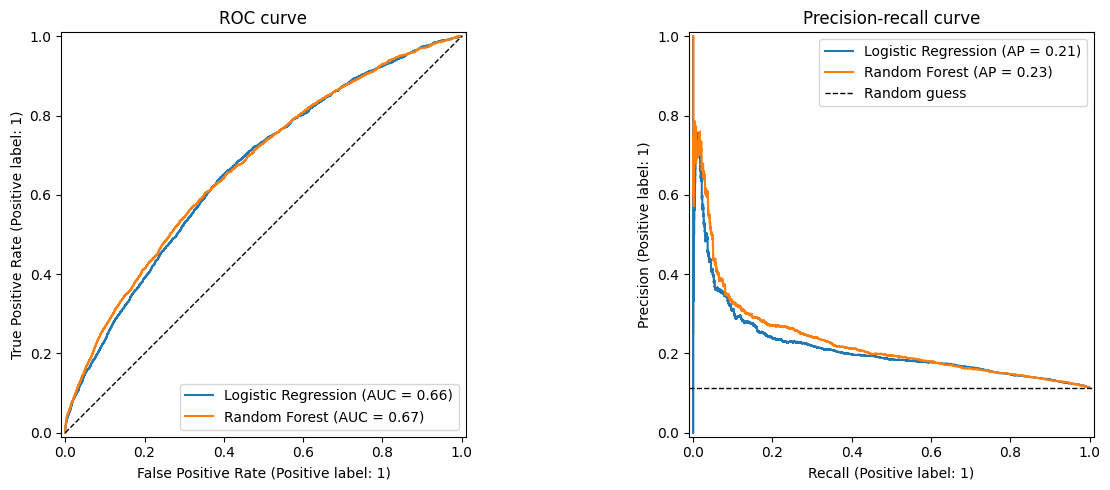

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(y_test, p_lr, name='Logistic Regression', ax=axes[0])
RocCurveDisplay.from_predictions(y_test, p_rf, name='Random Forest', ax=axes[0])
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[0].set_title('ROC curve')

PrecisionRecallDisplay.from_predictions(y_test, p_lr, name='Logistic Regression', ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, p_rf, name='Random Forest', ax=axes[1])
axes[1].axhline(y_test.mean(), color='k', linestyle='--', linewidth=1, label='Random guess')
axes[1].legend()
axes[1].set_title('Precision-recall curve')
plt.tight_layout()
plt.savefig(FIG + '05_roc_pr.png', dpi=150, bbox_inches='tight')
plt.show()

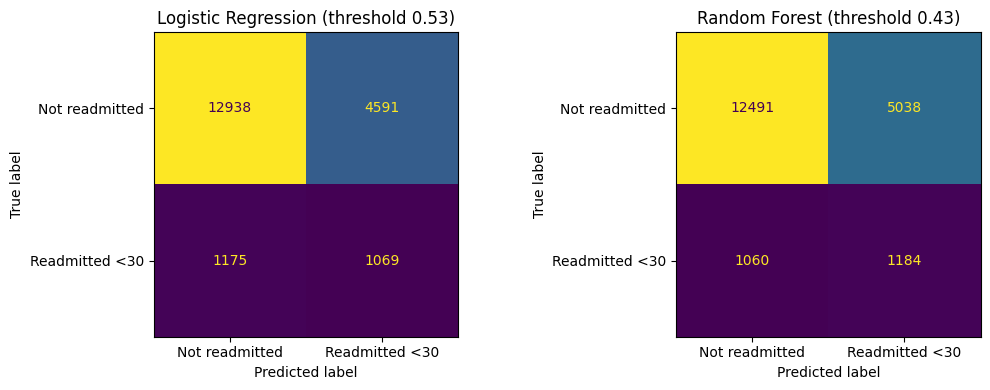

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, p, t) in zip(axes, [('Logistic Regression', p_lr, lr['threshold']),
                                   ('Random Forest', p_rf, rf['threshold'])]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (p >= t).astype(int), ax=ax, colorbar=False,
        display_labels=['Not readmitted', 'Readmitted <30'])
    ax.set_title(f'{name} (threshold {t:.2f})')
plt.tight_layout()
plt.savefig(FIG + '05_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

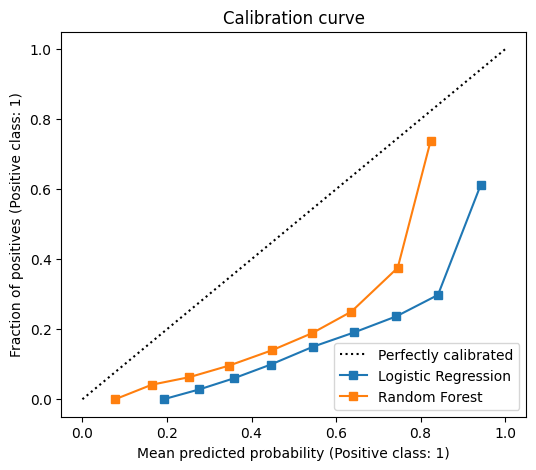

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
CalibrationDisplay.from_predictions(y_test, p_lr, n_bins=10, name='Logistic Regression', ax=ax)
CalibrationDisplay.from_predictions(y_test, p_rf, n_bins=10, name='Random Forest', ax=ax)
ax.set_title('Calibration curve')
plt.savefig(FIG + '05_calibration.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
rng = np.random.default_rng(42)
y_arr = y_test.to_numpy()
n = len(y_arr)
auc_lr, auc_rf, diff = [], [], []

for _ in range(1000):
    idx = rng.integers(0, n, n)
    if y_arr[idx].sum() == 0:
        continue
    a, b = roc_auc_score(y_arr[idx], p_lr[idx]), roc_auc_score(y_arr[idx], p_rf[idx])
    auc_lr.append(a); auc_rf.append(b); diff.append(b - a)

def ci(values):
    return np.percentile(values, [2.5, 97.5])

print('LR AUC 95% CI:', ci(auc_lr).round(4))
print('RF AUC 95% CI:', ci(auc_rf).round(4))
print('RF - LR difference 95% CI:', ci(diff).round(4))

LR AUC 95% CI: [0.6536 0.6763]
RF AUC 95% CI: [0.6591 0.6822]
RF - LR difference 95% CI: [0.0002 0.0125]


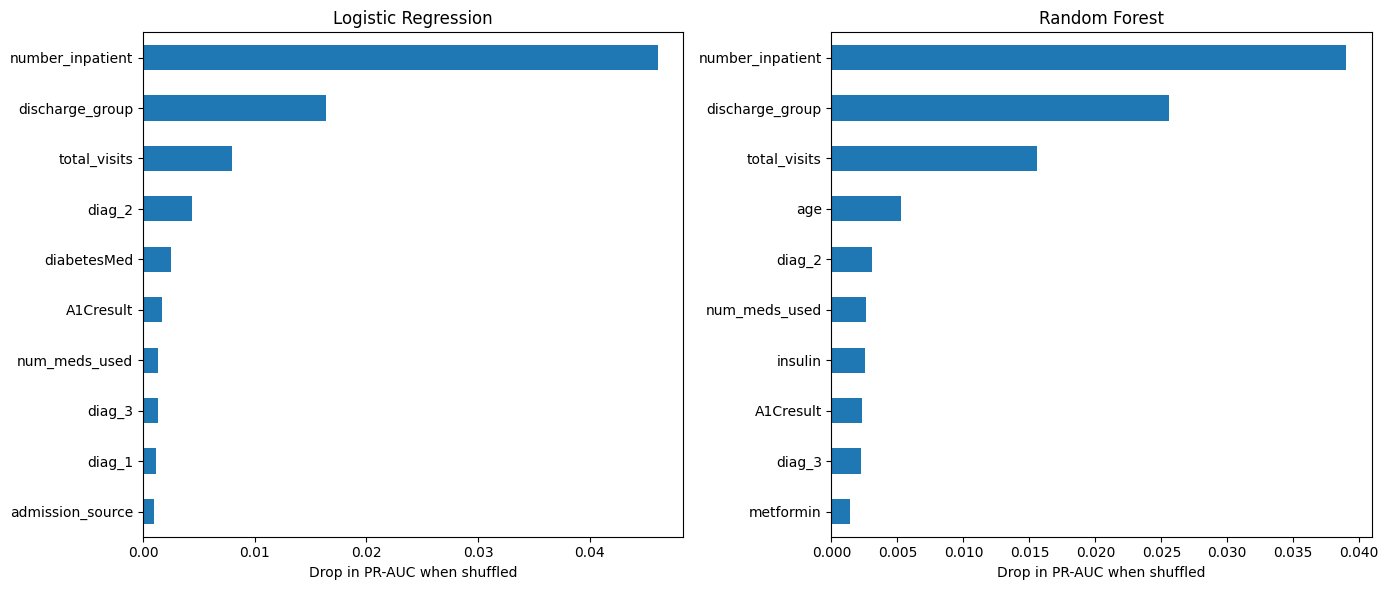

In [9]:
sample = X_test.sample(5000, random_state=42)
y_sample = y_test.loc[sample.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, m) in zip(axes, [('Logistic Regression', lr['model']), ('Random Forest', rf['model'])]):
    r = permutation_importance(m, sample, y_sample, scoring='average_precision',
                               n_repeats=5, random_state=42, n_jobs=-1)
    imp = pd.Series(r.importances_mean, index=sample.columns).sort_values().tail(10)
    imp.plot(kind='barh', ax=ax, title=name)
    ax.set_xlabel('Drop in PR-AUC when shuffled')
plt.tight_layout()
plt.savefig(FIG + '05_permutation.png', dpi=150, bbox_inches='tight')
plt.show()